Explicación para tu informe
- Tipo de aprendizaje: supervisado, porque el conjunto sintético incluye una variable objetivo conocida.
- Tarea: regresión, porque se estima una cantidad numérica.
- Modelo: regresión lineal múltiple, con tres variables predictoras.
- MAE: mide el error absoluto medio entre las predicciones y los valores reales sintéticos.
- R²: evalúa el ajuste del modelo respecto de una predicción basada en la media.
- Gráfico: permite comparar los valores reales sintéticos con los predichos. Cuanto más cerca estén los puntos de la línea ideal, mejor será el ajuste.
Los valores de MAE y R² se calcularán al ejecutar el notebook; no conviene inventar resultados antes de ejecutarlo.

PRIMERAS MUESTRAS DEL CONJUNTO SINTETICO
   Densidad  Senal_espectral  Temperatura  Contenido_mineral
0  4.247241        67.782848   -34.531420          37.281771
1  7.704286        17.572597    85.382936          38.828301
2  6.391964        24.546584    25.787856          37.259616
3  5.591951        90.869877    73.968620          46.092124
4  2.936112        64.578615    -1.992560          29.204116

Datos de entrenamiento: 160
Datos de prueba: 40

RESULTADOS DEL MODELO
MAE: 2.11
R2: 0.949

COEFICIENTES DEL MODELO
Densidad: 4.929
Senal_espectral: 0.243
Temperatura: -0.012
Intercepto: 0.326


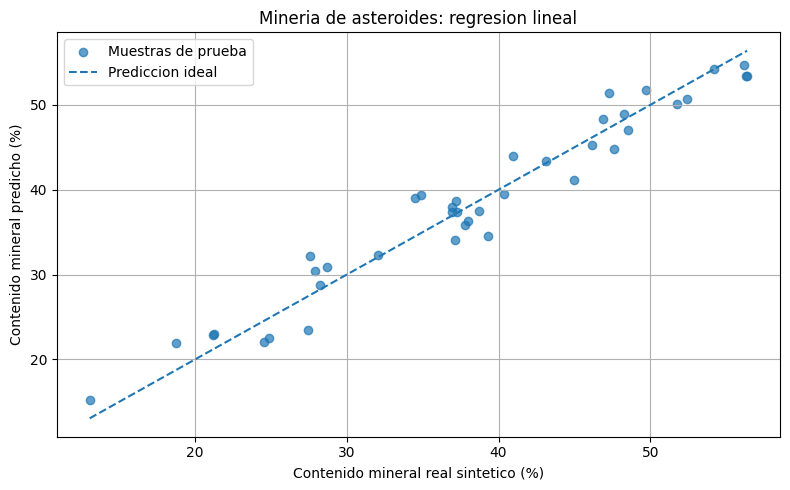


INTERPRETACION
El error absoluto medio es 2.11 puntos porcentuales.
El valor R2 obtenido es 0.949.
El modelo explica gran parte de la variabilidad sintetica.
La evaluacion solo corresponde a datos sinteticos.


In [1]:

# ==========================================================
# CHALLENGE 1 - MINERIA DE ASTEROIDES
# PIPELINE DE PREDICCION Y VISUALIZACION
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# 1. GENERACION DE DATOS SINTETICOS
# No se necesita archivo CSV externo.

np.random.seed(42)
n = 200

densidad = np.random.uniform(2, 8, n)
senal_espectral = np.random.uniform(10, 100, n)
temperatura = np.random.uniform(-50, 100, n)

ruido = np.random.normal(0, 3, n)

# Variable objetivo sintética, definida para este ejercicio.
contenido_mineral = (
    5 * densidad
    + 0.25 * senal_espectral
    - 0.02 * temperatura
    + ruido
)

contenido_mineral = np.clip(contenido_mineral, 0, 100)

datos = pd.DataFrame({
    "Densidad": densidad,
    "Senal_espectral": senal_espectral,
    "Temperatura": temperatura,
    "Contenido_mineral": contenido_mineral
})

print("PRIMERAS MUESTRAS DEL CONJUNTO SINTETICO")
print(datos.head())

# 2. DEFINICION DE VARIABLES

X = datos[[
    "Densidad",
    "Senal_espectral",
    "Temperatura"
]]

y = datos["Contenido_mineral"]

# 3. DIVISION ENTRE ENTRENAMIENTO Y PRUEBA

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nDatos de entrenamiento:", len(X_train))
print("Datos de prueba:", len(X_test))

# 4. ENTRENAMIENTO DEL MODELO

modelo = LinearRegression()
modelo.fit(X_train, y_train)

# 5. PREDICCION

predicciones = modelo.predict(X_test)

# 6. EVALUACION

mae = mean_absolute_error(y_test, predicciones)
r2 = r2_score(y_test, predicciones)

print("\nRESULTADOS DEL MODELO")
print("MAE:", round(mae, 2))
print("R2:", round(r2, 3))

print("\nCOEFICIENTES DEL MODELO")
for variable, coeficiente in zip(X.columns, modelo.coef_):
    print(f"{variable}: {coeficiente:.3f}")

print("Intercepto:", round(modelo.intercept_, 3))

# 7. GRAFICO: VALORES REALES VS PREDICHOS

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    predicciones,
    alpha=0.7,
    label="Muestras de prueba"
)

limite_min = min(y_test.min(), predicciones.min())
limite_max = max(y_test.max(), predicciones.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--",
    label="Prediccion ideal"
)

plt.xlabel("Contenido mineral real sintetico (%)")
plt.ylabel("Contenido mineral predicho (%)")
plt.title("Mineria de asteroides: regresion lineal")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 8. INTERPRETACION AUTOMATICA

print("\nINTERPRETACION")
print(f"El error absoluto medio es {mae:.2f} puntos porcentuales.")
print(f"El valor R2 obtenido es {r2:.3f}.")

if r2 >= 0.8:
    print("El modelo explica gran parte de la variabilidad sintetica.")
elif r2 >= 0.5:
    print("El modelo presenta capacidad explicativa moderada.")
else:
    print("El modelo presenta capacidad explicativa limitada.")

print("La evaluacion solo corresponde a datos sinteticos.")
